In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv(
    "../data/raw/transactions.csv",
    parse_dates=["transaction_timestamp"]
)

df.head()

,transaction_id,customer_id,transaction_timestamp,amount,merchant_category,channel,country,home_country,distance_from_home_km,account_age_days,transactions_last_1h,transactions_last_24h,device_change,is_fraud
0,TXN0005083,CUST00264,2026-01-01 00:00:00,26.83,Gas,ATM,UK,USA,11.11,1535,0,2,0,0
1,TXN0020436,CUST01838,2026-01-01 00:01:00,44.45,Retail,POS,USA,USA,108.96,1345,2,7,0,0
2,TXN0027687,CUST00275,2026-01-01 00:05:00,402.63,Travel,Mobile,USA,USA,9.95,3460,2,6,1,0
3,TXN0024982,CUST02425,2026-01-01 00:16:00,100.42,Gas,Mobile,Germany,USA,14.76,2319,2,11,0,1
4,TXN0026404,CUST00351,2026-01-01 00:25:00,155.47,Gas,POS,Germany,USA,104.66,3064,1,3,0,0


In [2]:
print(df.shape)

print(df.info())

display(df.describe(include="all"))

print(df.isnull().sum())

(30000, 14)
<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   transaction_id         30000 non-null  str           
 1   customer_id            30000 non-null  str           
 2   transaction_timestamp  30000 non-null  datetime64[us]
 3   amount                 30000 non-null  float64       
 4   merchant_category      30000 non-null  str           
 5   channel                30000 non-null  str           
 6   country                30000 non-null  str           
 7   home_country           30000 non-null  str           
 8   distance_from_home_km  30000 non-null  float64       
 9   account_age_days       30000 non-null  int64         
 10  transactions_last_1h   30000 non-null  int64         
 11  transactions_last_24h  30000 non-null  int64         
 12  device_change          30000 non-null  int64         
 13  

,transaction_id,customer_id,transaction_timestamp,amount,merchant_category,channel,country,home_country,distance_from_home_km,account_age_days,transactions_last_1h,transactions_last_24h,device_change,is_fraud
count,30000,30000,30000,30000.000000,30000,30000,30000,30000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000
unique,30000,3000,NaN,NaN,7,4,4,1,NaN,NaN,NaN,NaN,NaN,NaN
top,TXN0005083,CUST00724,NaN,NaN,Restaurant,Mobile,USA,USA,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,25,NaN,NaN,4369,10420,14965,30000,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,2026-02-14 21:23:49.410000,60.838152,NaN,NaN,NaN,NaN,29.793404,1996.126033,1.207533,5.199367,0.082100,0.041367
min,NaN,NaN,2026-01-01 00:00:00,0.490000,NaN,NaN,NaN,NaN,0.000000,10.000000,0.000000,0.000000,0.000000,0.000000
25%,NaN,NaN,2026-01-23 09:29:30,15.560000,NaN,NaN,NaN,NaN,8.550000,987.000000,0.000000,4.000000,0.000000,0.000000
50%,NaN,NaN,2026-02-14 22:22:00,32.610000,NaN,NaN,NaN,NaN,20.630000,1998.000000,1.000000,5.000000,0.000000,0.000000
75%,NaN,NaN,2026-03-09 07:05:30,69.020000,NaN,NaN,NaN,NaN,41.530000,2978.250000,2.000000,7.000000,0.000000,0.000000
max,NaN,NaN,2026-03-31 23:57:00,4709.890000,NaN,NaN,NaN,NaN,372.190000,3999.000000,8.000000,17.000000,1.000000,1.000000


transaction_id           0
customer_id              0
transaction_timestamp    0
amount                   0
merchant_category        0
channel                  0
country                  0
home_country             0
distance_from_home_km    0
account_age_days         0
transactions_last_1h     0
transactions_last_24h    0
device_change            0
is_fraud                 0
dtype: int64


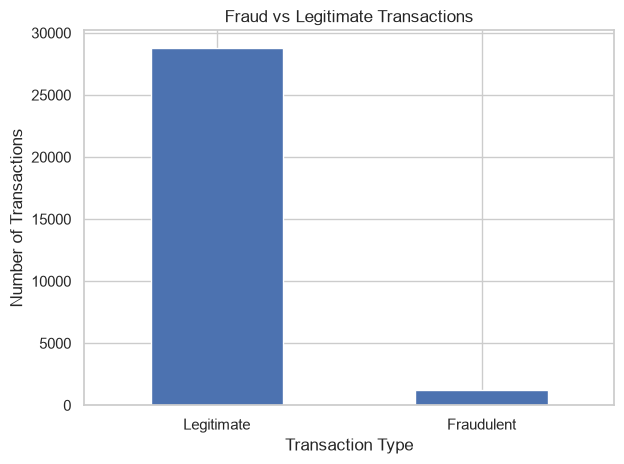

In [3]:
fraud_counts = df["is_fraud"].value_counts()

fraud_counts.plot(
    kind="bar",
    title="Fraud vs Legitimate Transactions"
)

plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate", "Fraudulent"], rotation=0)

plt.tight_layout()
plt.savefig(
    "../reports/figures/fraud_distribution.png",
    dpi=150
)
plt.show()

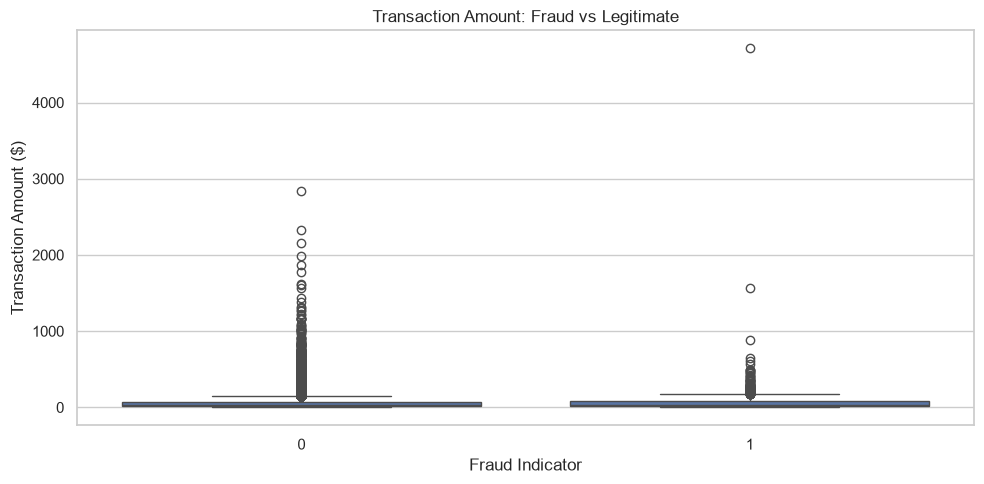

In [4]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="is_fraud",
    y="amount"
)

plt.title("Transaction Amount: Fraud vs Legitimate")
plt.xlabel("Fraud Indicator")
plt.ylabel("Transaction Amount ($)")

plt.tight_layout()
plt.savefig(
    "../reports/figures/transaction_amount_analysis.png",
    dpi=150
)
plt.show()

,channel,count,sum,mean,fraud_rate
0,ATM,2991,145,0.048479,4.847877
1,Mobile,10420,431,0.041363,4.136276
2,POS,9055,367,0.040530,4.053009
3,Web,7534,298,0.039554,3.955402


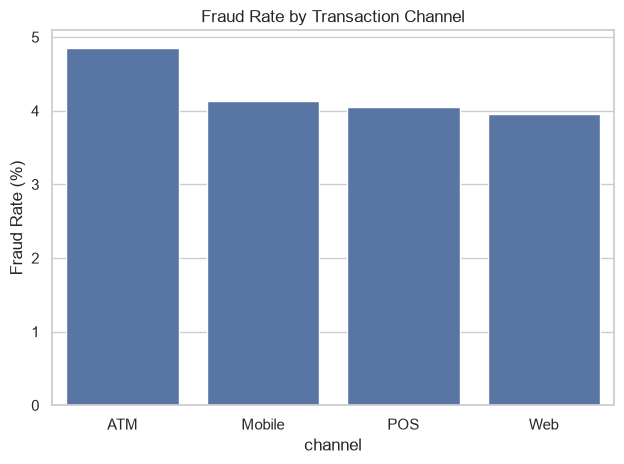

In [5]:
channel_analysis = (
    df.groupby("channel")["is_fraud"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

channel_analysis["fraud_rate"] = (
    channel_analysis["mean"] * 100
)

display(channel_analysis)

sns.barplot(
    data=channel_analysis,
    x="channel",
    y="fraud_rate"
)

plt.title("Fraud Rate by Transaction Channel")
plt.ylabel("Fraud Rate (%)")

plt.tight_layout()
plt.savefig(
    "../reports/figures/fraud_by_channel.png",
    dpi=150
)
plt.show()

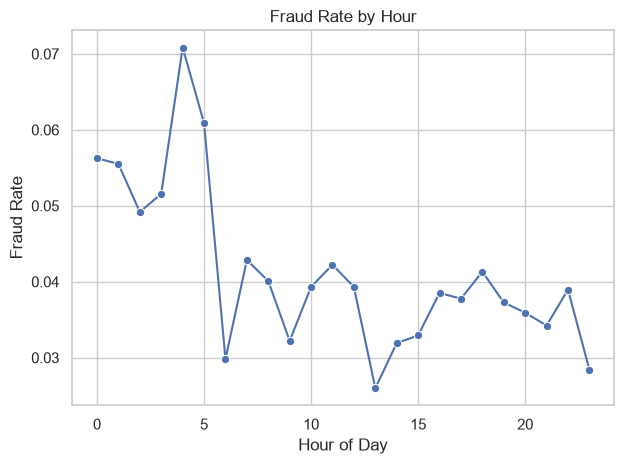

In [6]:
df["transaction_hour"] = (
    df["transaction_timestamp"].dt.hour
)

hour_analysis = (
    df.groupby("transaction_hour")["is_fraud"]
    .mean()
    .reset_index()
)

sns.lineplot(
    data=hour_analysis,
    x="transaction_hour",
    y="is_fraud",
    marker="o"
)

plt.title("Fraud Rate by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Fraud Rate")

plt.tight_layout()
plt.savefig(
    "../reports/figures/fraud_by_hour.png",
    dpi=150
)
plt.show()